<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/main/notebooks/13_improved_xgboost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13 — Improved XGBoost: arithmetic features + monotonic constraints + screening threshold
**Project:** Explainable AI-Based Dyscalculia Screening and Adaptive Personalized Mathematics Intervention
**Stage 1:** Dyscalculia risk screening (DD vs TA) — OpenNeuro ds004791, 68 children aged 8–10

Notebooks 01–11 showed that all 10 models plateau at ROC-AUC ≈ 0.74. This notebook tests three
**theory-driven** improvements to the proposed XGBoost model, all evaluated with the **same honest nested CV**
(same 50 outer splits from notebook 00, tuning only inside the training folds, no synthetic data):

| # | Improvement | Why (theory) |
|---|---|---|
| 1 | **Arithmetic feature set** (6 features: accuracy + median RT of SmallProblem, LargeProblem, Plus1) | Dyscalculia is defined by a deficit in arithmetic (fact retrieval accuracy and speed). With only 68 children, extra domain-general features add more noise than signal. |
| 2 | **Monotonic constraints** in XGBoost | Known direction from research: *lower* arithmetic accuracy and *slower* responses can only *raise* risk. This removes implausible zig-zag patterns and is a strong regulariser for small samples. It also makes SHAP explanations consistent. |
| 3 | **Screening threshold** chosen inside each training fold for ≈ 80 % sensitivity | In screening, a missed DD child is the costly error. The threshold is learned from the training children only and then applied to the test children. |

**Models compared (all nested CV):**
A = original XGBoost (12 features, notebook 02) · B = XGBoost on the arithmetic features ·
**C = monotonic XGBoost on the arithmetic features (improved, proposed)** · D = logistic regression on the arithmetic features (baseline)

*Expected runtime on a standard Colab CPU runtime: about 6–12 minutes.*

## 1. Install missing packages
Colab already ships with numpy, pandas, scikit-learn, matplotlib, seaborn, XGBoost and LightGBM.
This cell only installs the packages that are missing in the current runtime, so it is safe to re-run.

In [ ]:
import importlib, subprocess, sys

REQUIRED = [
    ("sklearn", "scikit-learn"),
    ("xgboost", "xgboost"),
    ("lightgbm", "lightgbm"),
    ("joblib", "joblib"),
]
for import_name, pip_name in REQUIRED:
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
print("All required packages are available.")

All required packages are available.


## 2. Mount Google Drive and set the project folder
All notebooks share one project folder on Google Drive:

```
/content/drive/MyDrive/Dyscalculia_Stage1/
├── data/      ds004791_features.csv + shared configuration (features, X/y, CV splits)
├── results/   per-model metrics (.json) and out-of-fold probabilities (.csv)
├── models/    final models refit on all children (.joblib)
└── figures/   all plots
```
When the notebook is run outside Colab, a local `Dyscalculia_Stage1/` folder is used instead
(or the folder given by the `STAGE1_PROJECT_DIR` environment variable).

In [ ]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Dyscalculia_Stage1'
except ImportError:  # running locally / outside Colab
    PROJECT_DIR = os.environ.get('STAGE1_PROJECT_DIR', os.path.abspath('Dyscalculia_Stage1'))

DATA_DIR    = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
FIGURES_DIR = os.path.join(PROJECT_DIR, 'figures')
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

CONFIG_PATH = os.path.join(DATA_DIR, 'stage1_config.joblib')
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Dyscalculia_Stage1


## 3. Imports

In [ ]:
import json, time, warnings
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import xgboost
from xgboost import XGBClassifier
print('XGBoost', xgboost.__version__)

warnings.filterwarnings('ignore')        # silence convergence / future warnings in the long CV loops
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(42)
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

XGBoost 3.4.1


## 4. Load the shared configuration from notebook 00 and the raw arithmetic columns
The outer CV splits, labels and child order come from notebook 00 (nothing is re-split).
`Plus1_rt` is not in the 12-feature set of notebook 00, so the six arithmetic columns are read from the
original `ds004791_features.csv` in the `data/` folder (same row order, checked below).

In [ ]:
assert os.path.exists(CONFIG_PATH), 'Run 00_setup_and_data.ipynb first - shared config not found.'
cfg = joblib.load(CONFIG_PATH)

X_ORIG       = cfg['X']                # 12 original features (notebook 00)
y            = cfg['y']
FEATURES_ORIG = cfg['features']
IDS          = cfg['ids']
OUTER_SPLITS = cfg['outer_splits']
N_SPLITS, N_REPEATS = cfg['n_splits'], cfg['n_repeats']
RANDOM_STATE = cfg['random_state']

ARITH_FEATURES = ['SmallProblem_acc', 'LargeProblem_acc', 'Plus1_acc',
                  'SmallProblem_rt', 'LargeProblem_rt', 'Plus1_rt']
raw = pd.read_csv(os.path.join(DATA_DIR, 'ds004791_features.csv'))
if cfg['id_col']:
    assert (raw[cfg['id_col']].astype(str).values == IDS).all(), 'Row order differs from notebook 00'
assert (raw['label_dd'].values == y).all()
X_ARITH = raw[ARITH_FEATURES].astype(float).reset_index(drop=True)

# The shared utilities below use the globals X and FEATURES -> start with the improved feature set
X, FEATURES = X_ARITH, ARITH_FEATURES
print(f'Children: {len(y)}  (DD = {int(y.sum())}, TA = {int((y == 0).sum())})')
print('Arithmetic features:', ARITH_FEATURES)
print(f'Outer CV: {N_SPLITS} folds x {N_REPEATS} repeats = {len(OUTER_SPLITS)} train/test splits')

Children: 68  (DD = 30, TA = 38)
Arithmetic features: ['SmallProblem_acc', 'LargeProblem_acc', 'Plus1_acc', 'SmallProblem_rt', 'LargeProblem_rt', 'Plus1_rt']
Outer CV: 5 folds x 10 repeats = 50 train/test splits


## 5. Shared evaluation utilities (identical to the model notebooks)

In [ ]:
INNER_SPLITS = 3       # inner grid-search folds
N_JOBS       = -1      # parallelise the grid search over all CPU cores
THRESHOLD    = 0.5     # probability threshold for flagging a child as at-risk

METRICS = ['auc', 'recall', 'specificity', 'balanced_accuracy', 'precision', 'f1']
METRIC_LABELS = {'auc': 'ROC-AUC', 'recall': 'Recall (sensitivity)', 'specificity': 'Specificity',
                 'balanced_accuracy': 'Balanced accuracy', 'precision': 'Precision', 'f1': 'F1'}


def classification_metrics(y_true, prob, threshold=THRESHOLD):
    """All screening metrics for one test fold (DD = positive class)."""
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    recall      = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    precision   = tp / (tp + fp) if (tp + fp) else 0.0       # zero_division = 0 convention
    f1          = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {'auc': roc_auc_score(y_true, prob), 'recall': recall, 'specificity': specificity,
            'balanced_accuracy': (recall + specificity) / 2, 'precision': precision, 'f1': f1}


def predict_dd_probability(estimator, X_new):
    """P(DD) for each child. Models without predict_proba (the SVM) get a logistic transform of their
    decision score, so 0.5 sits exactly on the decision boundary and the ranking matches the score."""
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(X_new)[:, 1]
    return 1.0 / (1.0 + np.exp(-estimator.decision_function(X_new)))


def _jsonable(params):
    """Convert hyperparameter values (e.g. tuples) into JSON-friendly types."""
    return {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in params.items()}


def run_nested_cv(build_estimator, param_grid, fit_params_fn=None, verbose=True):
    """Nested CV over the saved outer splits.

    build_estimator(y_train) -> unfitted sklearn estimator/pipeline (y_train lets us set class weights
                                 such as scale_pos_weight from the training fold only)
    fit_params_fn(y_train)   -> optional dict of fit parameters (e.g. sample weights)
    Returns per-fold metrics, out-of-fold probabilities and the runtime in seconds.
    """
    fold_rows, oof_rows = [], []
    t0 = time.time()
    for s in OUTER_SPLITS:
        tr, te = s['train_idx'], s['test_idx']
        X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]

        inner_cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE + s['split_id'])
        search = GridSearchCV(build_estimator(y_tr), param_grid, scoring='roc_auc', cv=inner_cv,
                              n_jobs=N_JOBS, refit=True, error_score='raise')
        fit_params = fit_params_fn(y_tr) if fit_params_fn is not None else {}
        search.fit(X_tr, y_tr, **fit_params)
        prob = predict_dd_probability(search, X_te)

        fold_rows.append({'split_id': s['split_id'], 'repeat': s['repeat'], 'fold': s['fold'],
                          **classification_metrics(y_te, prob),
                          'inner_best_auc': search.best_score_,
                          'best_params': _jsonable(search.best_params_)})
        for i, p in zip(te, prob):
            oof_rows.append({'row_index': int(i), 'child_id': IDS[i], 'repeat': s['repeat'], 'fold': s['fold'],
                             'y_true': int(y[i]), 'prob_dd': float(p)})

        if verbose and s['fold'] == N_SPLITS - 1:
            done = pd.DataFrame(fold_rows)
            print(f"Repeat {s['repeat'] + 1:2d}/{N_REPEATS} done | running mean AUC = {done['auc'].mean():.3f} "
                  f"| elapsed {time.time() - t0:.0f}s")
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows), time.time() - t0


def summarise(fold_df):
    """Mean +- SD over the outer folds for every metric."""
    rows = []
    for m in METRICS:
        mean, sd = fold_df[m].mean(), fold_df[m].std(ddof=1)
        rows.append({'Metric': METRIC_LABELS[m], 'Mean': mean, 'SD': sd, 'Mean ± SD': f'{mean:.3f} ± {sd:.3f}'})
    return pd.DataFrame(rows).set_index('Metric')


def repeat_pooled_auc(oof_df):
    """AUC of the pooled out-of-fold predictions within each repeat (each repeat covers every child once)."""
    return oof_df.groupby('repeat').apply(lambda d: roc_auc_score(d['y_true'], d['prob_dd'])).values


def child_level_oof(oof_df):
    """Average each child's out-of-fold probability over the 10 repeats."""
    return oof_df.groupby(['row_index', 'child_id', 'y_true'], as_index=False)['prob_dd'].mean()


def hyperparameter_stability(fold_df, top=5):
    """How often each hyperparameter combination was chosen by the inner grid search."""
    counts = fold_df['best_params'].apply(lambda p: json.dumps(p, sort_keys=True)).value_counts()
    out = counts.head(top).rename('times chosen (of %d)' % len(fold_df)).to_frame()
    out.index.name = 'hyperparameters'
    return out


def fit_final_model(build_estimator, param_grid, fit_params_fn=None):
    """Tune on ALL children (3-fold grid search) and refit - this is the deployable model.
    Its performance is the nested-CV estimate above, NOT its (optimistic) training score."""
    cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    search = GridSearchCV(build_estimator(y), param_grid, scoring='roc_auc', cv=cv, n_jobs=N_JOBS, refit=True)
    search.fit(X, y, **(fit_params_fn(y) if fit_params_fn is not None else {}))
    return search


def save_outputs(model_name, display_name, fold_df, oof_df, final_search, param_grid, runtime):
    summary = {m: {'mean': float(fold_df[m].mean()), 'sd': float(fold_df[m].std(ddof=1))} for m in METRICS}
    child = child_level_oof(oof_df)
    results = {
        'model_name': model_name,
        'display_name': display_name,
        'n_children': int(len(y)), 'n_dd': int(y.sum()), 'n_ta': int((y == 0).sum()),
        'features': FEATURES,
        'outer_cv': f'RepeatedStratifiedKFold({N_SPLITS} folds x {N_REPEATS} repeats, random_state={RANDOM_STATE})',
        'inner_cv': f'StratifiedKFold({INNER_SPLITS}) grid search, scoring=roc_auc',
        'threshold': THRESHOLD,
        'param_grid': {k: [str(v) if not isinstance(v, (int, float, str, bool, type(None))) else v for v in vals]
                       for k, vals in param_grid.items()},
        'summary': summary,
        'fold_auc': fold_df['auc'].tolist(),
        'fold_metrics': fold_df.to_dict(orient='records'),
        'repeat_pooled_auc': repeat_pooled_auc(oof_df).tolist(),
        'child_mean_prob_auc': float(roc_auc_score(child['y_true'], child['prob_dd'])),
        'final_model_best_params': _jsonable(final_search.best_params_),
        'final_model_inner_cv_auc': float(final_search.best_score_),
        'runtime_seconds': float(runtime),
        'created': datetime.now().isoformat(timespec='seconds'),
    }
    paths = {'json': os.path.join(RESULTS_DIR, f'{model_name}.json'),
             'oof':  os.path.join(RESULTS_DIR, f'{model_name}_oof.csv'),
             'model': os.path.join(MODELS_DIR, f'{model_name}.joblib')}
    with open(paths['json'], 'w') as f:
        json.dump(results, f, indent=2, default=float)
    oof_df.to_csv(paths['oof'], index=False)
    joblib.dump(final_search.best_estimator_, paths['model'])
    for k, p in paths.items():
        print(f'Saved {k:5s} -> {p}')
    return results


def plot_confusion_matrix(model_name, display_name, oof_df):
    """Child-level confusion matrix: each child's out-of-fold probability averaged over the 10 repeats."""
    child = child_level_oof(oof_df)
    pred = (child['prob_dd'] >= THRESHOLD).astype(int)
    cm = confusion_matrix(child['y_true'], pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(cm, display_labels=['TA', 'DD']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{display_name}\nSensitivity {tp / (tp + fn):.2f} | Specificity {tn / (tn + fp):.2f}', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    fig.tight_layout()
    path = os.path.join(FIGURES_DIR, f'{model_name}_confusion_matrix.png')
    fig.savefig(path, dpi=200, bbox_inches='tight'); plt.show()
    print('Saved ->', path)


def mean_roc(oof_df, grid=np.linspace(0, 1, 101)):
    """Mean +- SD ROC curve over the repeats (one pooled out-of-fold ROC curve per repeat)."""
    tprs = []
    for _, d in oof_df.groupby('repeat'):
        fpr, tpr, _ = roc_curve(d['y_true'], d['prob_dd'])
        t = np.interp(grid, fpr, tpr); t[0] = 0.0
        tprs.append(t)
    tprs = np.array(tprs)
    return grid, tprs.mean(axis=0), tprs.std(axis=0, ddof=1), tprs


def plot_roc(model_name, display_name, oof_df, fold_df):
    grid, mean_tpr, sd_tpr, tprs = mean_roc(oof_df)
    fig, ax = plt.subplots(figsize=(5, 4.6))
    for t in tprs:
        ax.plot(grid, t, color='tab:blue', alpha=0.15, lw=1)
    ax.plot(grid, mean_tpr, color='tab:blue', lw=2.2,
            label=f"Mean ROC (fold AUC = {fold_df['auc'].mean():.3f} ± {fold_df['auc'].std(ddof=1):.3f})")
    ax.fill_between(grid, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
                    color='tab:blue', alpha=0.2, label='± 1 SD over repeats')
    ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Chance')
    ax.set_xlabel('False positive rate (1 - specificity)'); ax.set_ylabel('True positive rate (sensitivity)')
    ax.set_title(f'{display_name} - out-of-fold ROC ({N_REPEATS} repeats)', fontsize=10)
    ax.legend(loc='lower right', fontsize=8); ax.set_aspect('equal')
    fig.tight_layout()
    path = os.path.join(FIGURES_DIR, f'{model_name}_roc_curve.png')
    fig.savefig(path, dpi=200, bbox_inches='tight'); plt.show()
    print('Saved ->', path)

## 6. Nested CV with a screening threshold learned inside the training folds
For every outer split:
1. Grid search (inner stratified 3-fold, ROC-AUC) on the outer-training children → best model.
2. **Threshold:** 5-fold out-of-fold probabilities of the best configuration on the *outer-training* children only;
   the highest threshold that reaches the target sensitivity (80 %) is chosen.
3. The outer-test children are scored once, with both the default 0.5 threshold and the learned threshold.

The outer-test children are never used for tuning *or* for choosing the threshold.

In [ ]:
TARGET_SENSITIVITY = 0.80


def choose_threshold(y_true, prob, target=TARGET_SENSITIVITY):
    # Highest threshold whose sensitivity on these (training) children is >= target
    fpr, tpr, thr = roc_curve(y_true, prob)
    return float(min(thr[np.argmax(tpr >= target)], 1.0))


def run_nested_cv_thr(build_estimator, param_grid, X_mat, verbose=True):
    fold_rows, oof_rows = [], []
    t0 = time.time()
    for s in OUTER_SPLITS:
        tr, te = s['train_idx'], s['test_idx']
        X_tr, X_te, y_tr, y_te = X_mat.iloc[tr], X_mat.iloc[te], y[tr], y[te]

        inner_cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE + s['split_id'])
        search = GridSearchCV(build_estimator(y_tr), param_grid, scoring='roc_auc', cv=inner_cv,
                              n_jobs=N_JOBS, refit=True, error_score='raise')
        search.fit(X_tr, y_tr)

        thr_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + s['split_id'])
        prob_tr = cross_val_predict(search.best_estimator_, X_tr, y_tr, cv=thr_cv, method='predict_proba')[:, 1]
        thr = choose_threshold(y_tr, prob_tr)

        prob = predict_dd_probability(search, X_te)
        m05, mthr = classification_metrics(y_te, prob, 0.5), classification_metrics(y_te, prob, thr)
        fold_rows.append({'split_id': s['split_id'], 'repeat': s['repeat'], 'fold': s['fold'], **m05,
                          **{f'{k}_thr': v for k, v in mthr.items() if k != 'auc'},
                          'threshold': thr, 'inner_best_auc': search.best_score_,
                          'best_params': _jsonable(search.best_params_)})
        for i, p in zip(te, prob):
            oof_rows.append({'row_index': int(i), 'child_id': IDS[i], 'repeat': s['repeat'], 'fold': s['fold'],
                             'y_true': int(y[i]), 'prob_dd': float(p), 'threshold': thr, 'flag': int(p >= thr)})
        if verbose and s['fold'] == N_SPLITS - 1:
            done = pd.DataFrame(fold_rows)
            print(f"  repeat {s['repeat'] + 1:2d}/{N_REPEATS} | running AUC {done['auc'].mean():.3f} "
                  f"| elapsed {time.time() - t0:.0f}s")
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows), time.time() - t0

## 7. Model definitions
* XGBoost grid = notebook 02 grid plus `max_depth = 1` (decision stumps, a natural choice for 6 features).
* Monotonic constraints, in the order of `ARITH_FEATURES`: accuracy → **−1** (higher accuracy, lower risk),
  reaction time → **+1** (slower, higher risk).
* `scale_pos_weight = n_TA / n_DD` from each outer-training fold only.

In [ ]:
MONOTONE = {'SmallProblem_acc': -1, 'LargeProblem_acc': -1, 'Plus1_acc': -1,
            'SmallProblem_rt': +1, 'LargeProblem_rt': +1, 'Plus1_rt': +1}
MONO_STR = '(' + ','.join(str(MONOTONE[f]) for f in ARITH_FEATURES) + ')'


def make_xgb(monotone=None):
    def build(y_train):
        spw = (y_train == 0).sum() / (y_train == 1).sum()
        extra = {'monotone_constraints': monotone} if monotone else {}
        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('clf', XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                                  objective='binary:logistic', eval_metric='logloss', tree_method='hist',
                                  n_jobs=1, random_state=RANDOM_STATE, verbosity=0, **extra)),
        ])
    return build


def build_lr(y_train):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(class_weight='balanced', max_iter=5000))])


XGB_GRID_ORIG = {'clf__max_depth': [2, 3], 'clf__learning_rate': [0.03, 0.1],
                 'clf__n_estimators': [100, 300], 'clf__min_child_weight': [1, 3]}
XGB_GRID = {**XGB_GRID_ORIG, 'clf__max_depth': [1, 2, 3]}
LR_GRID = {'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3]}

EXPERIMENTS = {
    'A_xgb_original':        ('A: XGBoost, 12 original features',      make_xgb(),         XGB_GRID_ORIG, X_ORIG),
    'B_xgb_arith':           ('B: XGBoost, arithmetic features',       make_xgb(),         XGB_GRID,      X_ARITH),
    'C_xgb_monotone_arith':  ('C: Monotonic XGBoost, arithmetic (improved)', make_xgb(MONO_STR), XGB_GRID, X_ARITH),
    'D_lr_arith':            ('D: Logistic regression, arithmetic',    build_lr,           LR_GRID,       X_ARITH),
}
print('Monotonic constraints:', MONO_STR)

Monotonic constraints: (-1,-1,-1,1,1,1)


## 8. Run the four experiments

In [ ]:
runs = {}
for key, (label, build, grid, X_mat) in EXPERIMENTS.items():
    print(label)
    runs[key] = run_nested_cv_thr(build, grid, X_mat)
    print(f'  -> AUC {runs[key][0]["auc"].mean():.3f} ± {runs[key][0]["auc"].std(ddof=1):.3f} '
          f'in {runs[key][2] / 60:.1f} min\n')

A: XGBoost, 12 original features
  repeat  1/10 | running AUC 0.718 | elapsed 13s
  repeat  2/10 | running AUC 0.730 | elapsed 25s
  repeat  3/10 | running AUC 0.748 | elapsed 35s
  repeat  4/10 | running AUC 0.743 | elapsed 46s
  repeat  5/10 | running AUC 0.743 | elapsed 57s
  repeat  6/10 | running AUC 0.743 | elapsed 68s
  repeat  7/10 | running AUC 0.737 | elapsed 76s
  repeat  8/10 | running AUC 0.740 | elapsed 87s
  repeat  9/10 | running AUC 0.741 | elapsed 97s
  repeat 10/10 | running AUC 0.739 | elapsed 107s
  -> AUC 0.739 ± 0.112 in 1.8 min

B: XGBoost, arithmetic features
  repeat  1/10 | running AUC 0.773 | elapsed 14s
  repeat  2/10 | running AUC 0.765 | elapsed 28s
  repeat  3/10 | running AUC 0.782 | elapsed 41s
  repeat  4/10 | running AUC 0.764 | elapsed 54s
  repeat  5/10 | running AUC 0.762 | elapsed 67s
  repeat  6/10 | running AUC 0.764 | elapsed 81s
  repeat  7/10 | running AUC 0.761 | elapsed 95s
  repeat  8/10 | running AUC 0.767 | elapsed 109s
  repeat  9/10 |

## 9. Results
Mean ± SD over the 50 outer test folds. *@0.5* = default threshold; *@screening threshold* = threshold learned inside
the training folds for ≈ 80 % sensitivity. The p-value is the Nadeau–Bengio corrected resampled t-test of each model's
fold AUCs against model A (the original XGBoost), as in notebook 11.

In [ ]:
n_test = np.mean([len(s['test_idx']) for s in OUTER_SPLITS]); n_train = np.mean([len(s['train_idx']) for s in OUTER_SPLITS])
RATIO = n_test / n_train


def corrected_resampled_ttest(a, b, ratio=RATIO):
    d = np.asarray(a) - np.asarray(b)
    t = d.mean() / np.sqrt((1 / len(d) + ratio) * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), df=len(d) - 1)


def ms(s):
    return f'{s.mean():.3f} ± {s.std(ddof=1):.3f}'


ref = runs['A_xgb_original'][0]['auc']
rows = []
for key, (label, *_rest) in EXPERIMENTS.items():
    f, oof, _ = runs[key]
    diff, p = corrected_resampled_ttest(f['auc'], ref) if key != 'A_xgb_original' else (0.0, np.nan)
    rows.append({'Model': label, 'ROC-AUC': ms(f['auc']),
                 'Pooled AUC': f"{repeat_pooled_auc(oof).mean():.3f}",
                 'Sens @0.5': ms(f['recall']), 'Spec @0.5': ms(f['specificity']),
                 'Sens @screening thr.': ms(f['recall_thr']), 'Spec @screening thr.': ms(f['specificity_thr']),
                 'Bal. acc @screening thr.': ms(f['balanced_accuracy_thr']),
                 'AUC diff vs A': f'{diff:+.3f}', 'p vs A (corrected)': '' if np.isnan(p) else f'{p:.3f}',
                 'auc_mean': f['auc'].mean()})
table = pd.DataFrame(rows)
table.drop(columns='auc_mean').to_csv(os.path.join(RESULTS_DIR, '13_improvement_comparison.csv'), index=False)
display(table.drop(columns='auc_mean').set_index('Model'))
print('Saved ->', os.path.join(RESULTS_DIR, '13_improvement_comparison.csv'))

,ROC-AUC,Pooled AUC,Sens @0.5,Spec @0.5,Sens @screening thr.,Spec @screening thr.,Bal. acc @screening thr.,AUC diff vs A,p vs A (corrected)
Model,,,,,,,,,
"A: XGBoost, 12 original features",0.739 ± 0.112,0.724,0.637 ± 0.164,0.713 ± 0.146,0.773 ± 0.196,0.532 ± 0.209,0.653 ± 0.103,+0.000,
"B: XGBoost, arithmetic features",0.764 ± 0.113,0.739,0.633 ± 0.190,0.670 ± 0.139,0.787 ± 0.172,0.538 ± 0.174,0.662 ± 0.103,+0.026,0.530
"C: Monotonic XGBoost, arithmetic (improved)",0.778 ± 0.108,0.761,0.640 ± 0.173,0.693 ± 0.147,0.793 ± 0.156,0.580 ± 0.159,0.687 ± 0.089,+0.039,0.356
"D: Logistic regression, arithmetic",0.764 ± 0.120,0.747,0.607 ± 0.207,0.730 ± 0.177,0.797 ± 0.206,0.572 ± 0.163,0.684 ± 0.128,+0.025,0.593


Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/results/13_improvement_comparison.csv


## 10. Figures
1. ROC-AUC of the four experiments (mean ± SD over folds).
2. Out-of-fold ROC curve of the improved model.
3. Child-level confusion matrices of the improved model at 0.5 and at the screening threshold
   (each child counted once: flagged if flagged in the majority of the 10 repeats).

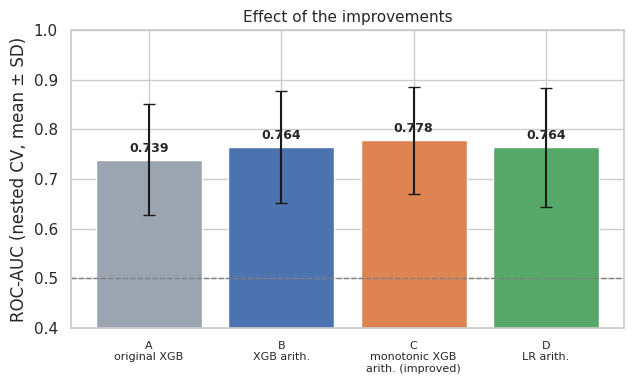

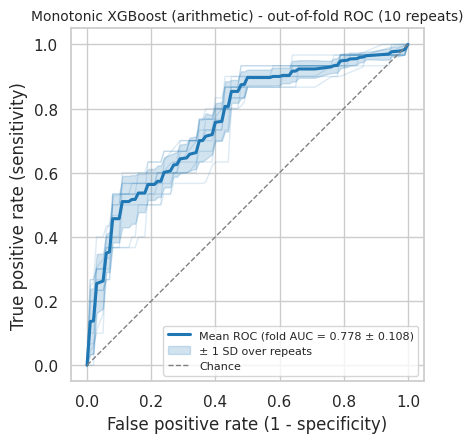

Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/figures/13_xgboost_monotone_arith_roc_curve.png


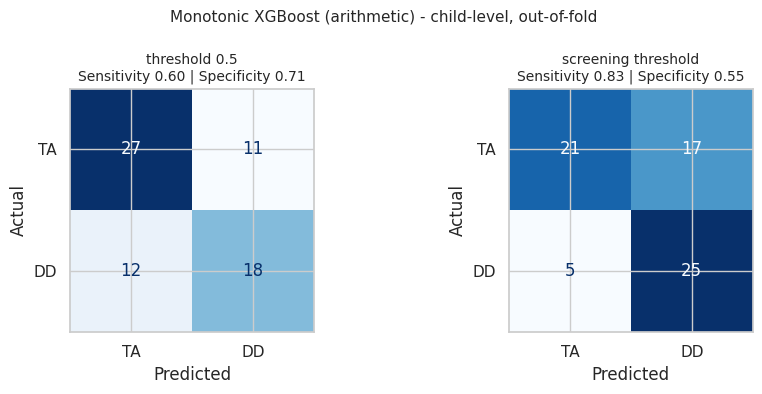

In [ ]:
BEST_KEY = 'C_xgb_monotone_arith'
labels = [EXPERIMENTS[k][0].split(':')[0] for k in EXPERIMENTS]
means = [runs[k][0]['auc'].mean() for k in EXPERIMENTS]; sds = [runs[k][0]['auc'].std(ddof=1) for k in EXPERIMENTS]
fig, ax = plt.subplots(figsize=(6.5, 4))
colors = ['#9AA5B1', '#4C72B0', '#DD8452', '#55A868']
ax.bar(labels, means, yerr=sds, capsize=4, color=colors)
for i, m in enumerate(means):
    ax.text(i, m + 0.01, f'{m:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(0.5, ls='--', color='grey', lw=1)
ax.set_ylim(0.4, 1.0); ax.set_ylabel('ROC-AUC (nested CV, mean ± SD)')
ax.set_title('Effect of the improvements', fontsize=11)
ax.set_xticklabels(['A\noriginal XGB', 'B\nXGB arith.', 'C\nmonotonic XGB\narith. (improved)', 'D\nLR arith.'], fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGURES_DIR, '13_improvement_auc.png'), dpi=200); plt.show()

fold_c, oof_c, _ = runs[BEST_KEY]
plot_roc('13_xgboost_monotone_arith', 'Monotonic XGBoost (arithmetic)', oof_c, fold_c)

child = oof_c.groupby(['row_index', 'y_true'], as_index=False).agg(prob_dd=('prob_dd', 'mean'), flag=('flag', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, pred) in zip(axes, [('threshold 0.5', (child['prob_dd'] >= 0.5).astype(int)),
                                    ('screening threshold', (child['flag'] >= 0.5).astype(int))]):
    cm = confusion_matrix(child['y_true'], pred, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
    ConfusionMatrixDisplay(cm, display_labels=['TA', 'DD']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{title}\nSensitivity {tp / (tp + fn):.2f} | Specificity {tn / (tn + fp):.2f}', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
fig.suptitle('Monotonic XGBoost (arithmetic) - child-level, out-of-fold', fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(FIGURES_DIR, '13_confusion_matrices.png'), dpi=200); plt.show()

## 11. Final improved model: refit on all children, choose the deployment threshold, save
* Hyperparameters: 3-fold grid search on all 68 children (as in the other notebooks).
* Deployment threshold: 5-fold out-of-fold probabilities on all children → threshold for ≈ 80 % sensitivity.
* **Expected performance on new children = the nested-CV numbers above**, not the training score.

Saved files: `models/xgboost_monotone_arith.joblib`, `results/xgboost_monotone_arith.json` (+ `_oof.csv`, same format
as the other models, so it can be added to notebook 11) and `results/xgboost_monotone_arith_threshold.json`.

In [ ]:
X, FEATURES = X_ARITH, ARITH_FEATURES
MODEL_NAME, DISPLAY_NAME = 'xgboost_monotone_arith', 'Monotonic XGBoost (arithmetic features)'
build_c = make_xgb(MONO_STR)

final_search = fit_final_model(build_c, XGB_GRID)
print('Final hyperparameters:', final_search.best_params_)

thr_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
prob_all = cross_val_predict(final_search.best_estimator_, X, y, cv=thr_cv, method='predict_proba')[:, 1]
FINAL_THRESHOLD = choose_threshold(y, prob_all)
print(f'Deployment screening threshold (target sensitivity {TARGET_SENSITIVITY:.0%}): {FINAL_THRESHOLD:.3f}')

oof_save = oof_c[['row_index', 'child_id', 'repeat', 'fold', 'y_true', 'prob_dd']]
results = save_outputs(MODEL_NAME, DISPLAY_NAME, fold_c[['split_id', 'repeat', 'fold'] + METRICS +
                                                       ['inner_best_auc', 'best_params']],
                       oof_save, final_search, XGB_GRID, runs[BEST_KEY][2])
thr_info = {'model_name': MODEL_NAME, 'features': ARITH_FEATURES, 'monotone_constraints': MONOTONE,
            'target_sensitivity': TARGET_SENSITIVITY, 'deployment_threshold': FINAL_THRESHOLD,
            'nested_cv_threshold_mean': float(fold_c['threshold'].mean()),
            'nested_cv_sensitivity_at_threshold': float(fold_c['recall_thr'].mean()),
            'nested_cv_specificity_at_threshold': float(fold_c['specificity_thr'].mean())}
with open(os.path.join(RESULTS_DIR, f'{MODEL_NAME}_threshold.json'), 'w') as f:
    json.dump(thr_info, f, indent=2)
print('Saved threshold ->', os.path.join(RESULTS_DIR, f'{MODEL_NAME}_threshold.json'))

Final hyperparameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__min_child_weight': 3, 'clf__n_estimators': 100}
Deployment screening threshold (target sensitivity 80%): 0.371
Saved json  -> /content/drive/MyDrive/Dyscalculia_Stage1/results/xgboost_monotone_arith.json
Saved oof   -> /content/drive/MyDrive/Dyscalculia_Stage1/results/xgboost_monotone_arith_oof.csv
Saved model -> /content/drive/MyDrive/Dyscalculia_Stage1/models/xgboost_monotone_arith.joblib
Saved threshold -> /content/drive/MyDrive/Dyscalculia_Stage1/results/xgboost_monotone_arith_threshold.json


## 12. Explainability: SHAP of the improved model
Exact TreeSHAP values (`pred_contribs`) of the final model. Thanks to the monotonic constraints, low accuracy always
pushes the risk **up** and fast responses always push it **down** — the explanation shown to teachers is never
counter-intuitive.

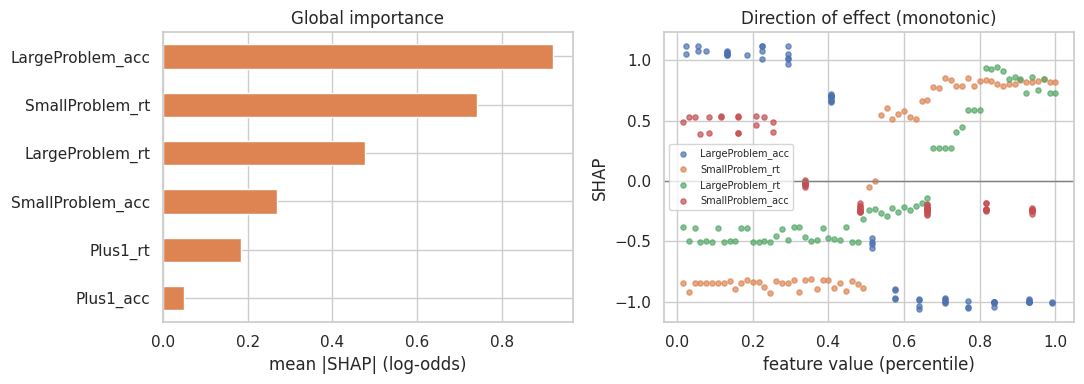

In [ ]:
clf = final_search.best_estimator_.named_steps['clf']
X_imp = final_search.best_estimator_.named_steps['imputer'].transform(X)
contribs = clf.get_booster().predict(xgboost.DMatrix(X_imp, feature_names=ARITH_FEATURES), pred_contribs=True)
shap_vals = pd.DataFrame(contribs[:, :-1], columns=ARITH_FEATURES)

imp = shap_vals.abs().mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
imp.plot.barh(ax=axes[0], color='#DD8452'); axes[0].set_xlabel('mean |SHAP| (log-odds)')
axes[0].set_title('Global importance')
for f in imp.index[::-1][:4]:
    axes[1].scatter(X[f].rank(pct=True), shap_vals[f], s=14, alpha=0.7, label=f)
axes[1].axhline(0, color='grey', lw=1); axes[1].set_xlabel('feature value (percentile)'); axes[1].set_ylabel('SHAP')
axes[1].set_title('Direction of effect (monotonic)'); axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(FIGURES_DIR, '13_shap_improved.png'), dpi=200); plt.show()
imp.sort_values(ascending=False).rename('mean_abs_shap').to_csv(os.path.join(RESULTS_DIR, '13_shap_importance.csv'))

## 13. Summary and honest reporting notes
* All numbers come from nested CV on the **68 real children** — no synthetic data, no tuning on test children.
* The arithmetic feature set and the monotonic directions were chosen from **dyscalculia theory**
  (arithmetic fact accuracy and speed are the core deficit). They were, however, compared with a few alternatives on
  this same dataset before this notebook was written, so the improvement may be **slightly optimistic**; the fold SD
  (≈ ±0.10) and the corrected p-value vs model A should be reported alongside it.
* Confirmation on new children (data collected with the app, or an external dataset) is the next step.

In [ ]:
fa, fc = runs['A_xgb_original'][0], runs[BEST_KEY][0]
_, p_ca = corrected_resampled_ttest(fc['auc'], fa['auc'])
print(f"Original XGBoost (12 features): AUC {ms(fa['auc'])} | sensitivity @0.5 {fa['recall'].mean():.2f}")
print(f"Improved monotonic XGBoost (6 arithmetic features): AUC {ms(fc['auc'])} "
      f"(corrected p vs original = {p_ca:.3f})")
print(f"  at the screening threshold: sensitivity {fc['recall_thr'].mean():.2f}, "
      f"specificity {fc['specificity_thr'].mean():.2f}, balanced accuracy {fc['balanced_accuracy_thr'].mean():.2f}")
print(f"Deployment threshold: {FINAL_THRESHOLD:.3f}")

Original XGBoost (12 features): AUC 0.739 ± 0.112 | sensitivity @0.5 0.64
Improved monotonic XGBoost (6 arithmetic features): AUC 0.778 ± 0.108 (corrected p vs original = 0.356)
  at the screening threshold: sensitivity 0.79, specificity 0.58, balanced accuracy 0.69
Deployment threshold: 0.371


In [ ]:
# Download the improved monotonic XGBoost model (notebook 13) with everything the backend needs
import os, json, shutil, joblib, sklearn, xgboost
import pandas as pd
from google.colab import drive, files

drive.mount('/content/drive')
D = '/content/drive/MyDrive/Dyscalculia_Stage1'
MODEL = f'{D}/models/xgboost_monotone_arith.joblib'
THRESH = f'{D}/results/xgboost_monotone_arith_threshold.json'
assert os.path.exists(MODEL), 'Model not found - run 13_improved_xgboost.ipynb first'

pipe = joblib.load(MODEL)
imputer, clf = pipe.named_steps['imputer'], pipe.named_steps['clf']
info = json.load(open(THRESH))
features = info['features']

out = '/content/xgboost_monotone_arith_export'
os.makedirs(out, exist_ok=True)
shutil.copy(MODEL, out)
clf.get_booster().save_model(f'{out}/xgboost_monotone_arith.json')
meta = {
    'model': 'Monotonic XGBoost on 6 arithmetic features (notebook 13)',
    'features': features,
    'imputer_medians': dict(zip(features, imputer.statistics_.tolist())),
    'monotone_constraints': info['monotone_constraints'],
    'screening_threshold': info['deployment_threshold'],
    'nested_cv': {'sensitivity': info['nested_cv_sensitivity_at_threshold'],
                  'specificity': info['nested_cv_specificity_at_threshold']},
    'hyperparameters': {k: v for k, v in clf.get_params().items()
                        if k in ('max_depth', 'learning_rate', 'n_estimators', 'min_child_weight',
                                 'subsample', 'colsample_bytree', 'scale_pos_weight')},
    'versions': {'xgboost': xgboost.__version__, 'scikit-learn': sklearn.__version__},
}
json.dump(meta, open(f'{out}/model_meta.json', 'w'), indent=2)

raw = pd.read_csv(f'{D}/data/ds004791_features.csv')
print('P(DD) for the first 5 children:', pipe.predict_proba(raw[features].head(5))[:, 1].round(3))
print(json.dumps(meta, indent=2))

shutil.make_archive(out, 'zip', out)
files.download(out + '.zip')

Mounted at /content/drive
P(DD) for the first 5 children: [0.868 0.51  0.526 0.926 0.812]
{
  "model": "Monotonic XGBoost on 6 arithmetic features (notebook 13)",
  "features": [
    "SmallProblem_acc",
    "LargeProblem_acc",
    "Plus1_acc",
    "SmallProblem_rt",
    "LargeProblem_rt",
    "Plus1_rt"
  ],
  "imputer_medians": {
    "SmallProblem_acc": 0.875,
    "LargeProblem_acc": 0.7083,
    "Plus1_acc": 0.9583,
    "SmallProblem_rt": 2557.0,
    "LargeProblem_rt": 3083.5,
    "Plus1_rt": 2009.0
  },
  "monotone_constraints": {
    "SmallProblem_acc": -1,
    "LargeProblem_acc": -1,
    "Plus1_acc": -1,
    "SmallProblem_rt": 1,
    "LargeProblem_rt": 1,
    "Plus1_rt": 1
  },
  "screening_threshold": 0.37086403369903564,
  "nested_cv": {
    "sensitivity": 0.7933333333333334,
    "specificity": 0.5803571428571428
  },
  "hyperparameters": {
    "colsample_bytree": 0.8,
    "learning_rate": 0.1,
    "max_depth": 2,
    "min_child_weight": 3,
    "n_estimators": 100,
    "scale_pos

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>